# Flow Matching from scratch

We train a small neural network to turn Gaussian noise into a 2D spiral by learning a velocity field and following it with an ODE solver.

Video: [Flow Matching from intuition to code](https://www.youtube.com/watch?v=SV0pGnbsl4g)

In [1]:
import math
import os
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image

In [2]:
BATCH_SIZE = 64
EPOCHS = 2_000
SEED = 0

In [3]:
torch.manual_seed(SEED)

Generate Spiral data as the data distribution $p_1$ we want to generate which is in $\mathbb{R}^2$.

In [4]:
def generate_spiral(n=1000, turns=1.5, radius=3.0):
    s = torch.sqrt(torch.rand(n)) * 2 * math.pi * turns   # position along the spiral
    arm = (torch.rand(n) < 0.5).float() * math.pi          # two arms, rotated 180°
    x1 = torch.stack([s * torch.cos(s + arm), s * torch.sin(s + arm)], dim=1)
    return x1 / (2 * math.pi * turns) * radius + 0.05 * torch.randn(n, 2)

In [5]:
# Plot style shared by every figure
BG, DATA, NOISE, GEN = "black", "#b56cff", "#ffd60a", "#00e5ff"
LIM = 4
os.makedirs("assets", exist_ok=True)

# Separate RNG for plot-only noise, so plotting does not change the training run
plot_gen = torch.Generator().manual_seed(1)


def new_fig(ncols=1, size=4):
    fig, axes = plt.subplots(1, ncols, figsize=(size * ncols, size), facecolor=BG)
    return fig, axes


def style_ax(ax, title=None):
    ax.set_facecolor(BG)
    ax.set_xlim(-LIM, LIM)
    ax.set_ylim(-LIM, LIM)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
    if title:
        ax.set_title(title, color="white", fontsize=13)


def scatter(ax, pts, color, s=4, alpha=0.8):
    ax.scatter(pts[:, 0], pts[:, 1], c=color, s=s, alpha=alpha, linewidths=0)


def save(fig, name):
    fig.savefig(f"assets/{name}.png", dpi=150, facecolor=BG, bbox_inches="tight")
    plt.show()

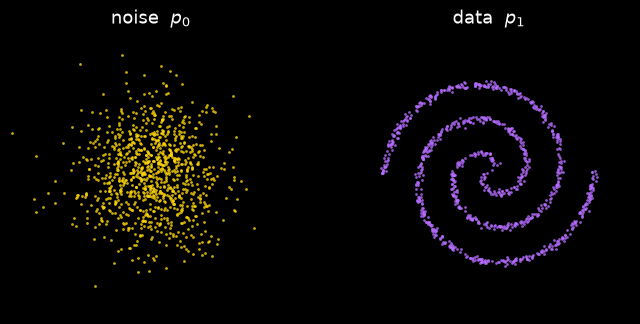

In [6]:
spiral = generate_spiral()

noise = torch.randn(1000, 2, generator=plot_gen)

fig, (ax0, ax1) = new_fig(2)
scatter(ax0, noise, NOISE)
style_ax(ax0, "noise  $p_0$")
scatter(ax1, spiral, DATA)
style_ax(ax1, "data  $p_1$")
save(fig, "data_and_noise")

In [7]:
dataset = TensorDataset(spiral)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

Flow Matching Network takes the current $x_t$ and time $t$, and predicts the vector field $v_\theta(x_t, t) \in \mathbb{R}^d$ (for us $\mathbb{R}^2$).

In [8]:
class FlowMatcher(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Linear(2, 256)
        self.mlp = nn.Sequential(
            nn.Linear(256, 512),
            nn.SiLU(),
            nn.Linear(512, 256),
            nn.SiLU(),
            nn.Linear(256, 2),
        )

    @staticmethod
    def time_embedding(t, dim=256, max_freq=1000):
        i = torch.arange(0, dim, 2) # (dim//2, )
        freqs = max_freq ** (i / dim) # (dim//2, )
        angles = t[:, None] * freqs[None, :] # (b, dim//2)
        
        return torch.cat([angles.sin(), angles.cos()], dim=-1)

    def forward(self, x, t):
        x_emb = self.embedding(x)
        t_emb = self.time_embedding(t)

        return self.mlp(x_emb + t_emb)

In [9]:
model = FlowMatcher()

In [10]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

We move each point on a straight line from noise $x_0 \sim p_0 = \mathcal{N}(0, I)$ to data $x_1 \sim p_1$:

$$x_t = t\,x_1 + (1-t)\,x_0$$

The arrow along it is $x_1 - x_0$. We train on the loss

$$\mathcal{L}_{\text{CFM}} = \mathbb{E}\,\big\| v_\theta(x_t, t) - (x_1 - x_0) \big\|^2$$

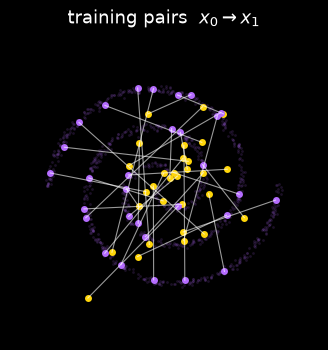

In [11]:
# 30 random training pairs: straight lines from noise x_0 to data x_1. The lines cross.
idx = torch.randint(len(spiral), (30,), generator=plot_gen)
x1_pairs = spiral[idx]
x0_pairs = torch.randn(30, 2, generator=plot_gen)

fig, ax = new_fig()
for a, b in zip(x0_pairs, x1_pairs):
    ax.plot([a[0], b[0]], [a[1], b[1]], color="white", lw=0.8, alpha=0.6)
scatter(ax, spiral, DATA, alpha=0.15)
scatter(ax, x0_pairs, NOISE, s=25, alpha=1)
scatter(ax, x1_pairs, DATA, s=25, alpha=1)
style_ax(ax, "training pairs  $x_0 \\to x_1$")
save(fig, "training_pairs")

In [12]:
losses = []  # mean loss per epoch

for e in range(EPOCHS):
    running_loss = 0
    running_steps = 0
    for x1 in dataloader:
        x1 = x1[0]
        x0 = torch.randn_like(x1)
        b = x1.size()[0]

        t = torch.rand(b)
        xt = t[:, None] * x1 + (1 - t[:, None]) * x0
        v = model(xt, t)

        loss = torch.mean((v - (x1 - x0))**2)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        running_loss += loss.item()
        running_steps += 1

    losses.append(running_loss / running_steps)

    if e % 500 == 0:
        print(f"Loss: {running_loss / running_steps:.4f}")

Loss: 3.0337


Loss: 2.3897


Loss: 2.2952


Loss: 2.3119


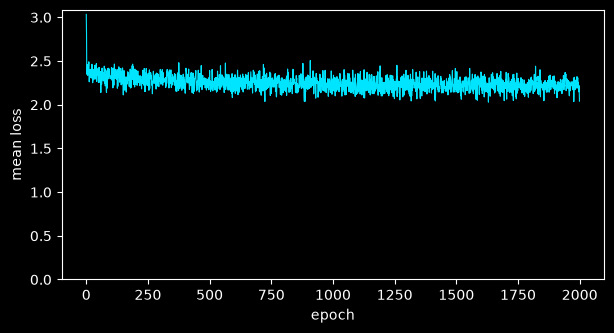

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5), facecolor=BG)
ax.plot(losses, color=GEN, lw=0.8)
ax.set_facecolor(BG)
ax.set_ylim(bottom=0)
ax.set_xlabel("epoch", color="white")
ax.set_ylabel("mean loss", color="white")
ax.tick_params(colors="white")
for spine in ax.spines.values():
    spine.set_color("white")
save(fig, "loss")

The loss plateaus above zero: the target $x_1 - x_0$ is noisy, and the network can only learn its average.

Euler sampling for the ODE $\dfrac{dx_t}{dt} = v_\theta(x_t, t)$.

In [14]:
@torch.no_grad()
def euler_path(x, steps=50):
    """Euler steps for dx_t/dt = v_theta(x_t, t). Returns every intermediate x."""
    dt = 1 / steps
    path = [x]
    for step in range(steps):
        t = torch.full((x.size(0),), step * dt)
        x = x + dt * model(x, t)
        path.append(x)
    return torch.stack(path)  # (steps + 1, n, 2)


@torch.no_grad()
def euler_sampler(samples=1000, steps=50):
    x = torch.randn(samples, 2)
    return euler_path(x, steps)[-1]

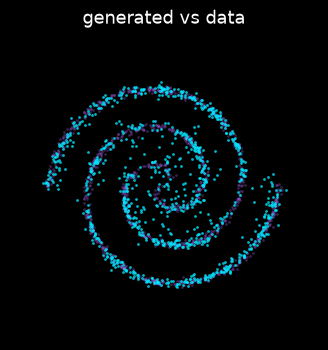

In [15]:
samples_spiral = euler_sampler()

fig, ax = new_fig()
scatter(ax, spiral, DATA, alpha=0.3)
scatter(ax, samples_spiral, GEN)
style_ax(ax, "generated vs data")
save(fig, "samples")

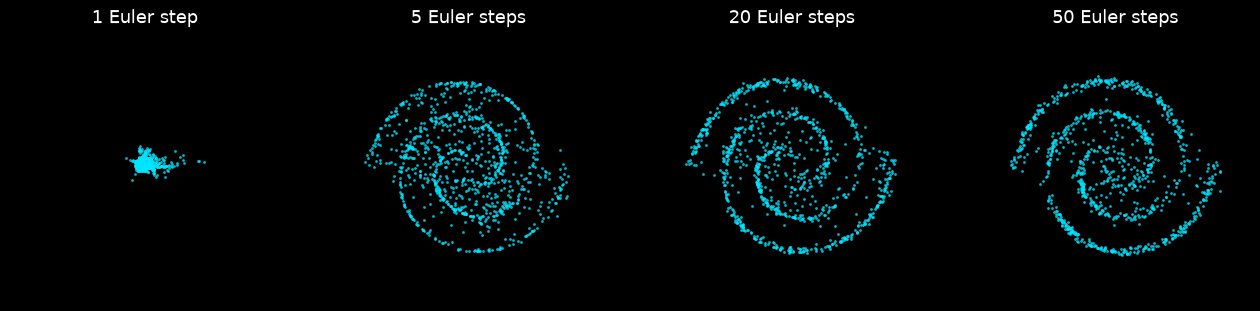

In [16]:
step_counts = [1, 5, 20, 50]
fig, axes = new_fig(len(step_counts))
for ax, steps in zip(axes, step_counts):
    scatter(ax, euler_sampler(steps=steps), GEN)
    style_ax(ax, f"{steps} Euler step{'s' if steps > 1 else ''}")
save(fig, "euler_steps")

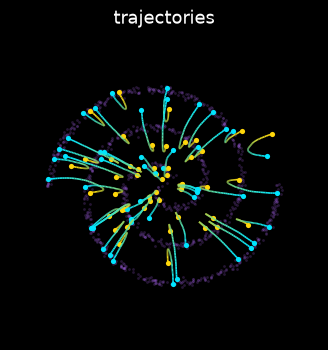

In [17]:
# 50 paths, each coloured from noise (yellow) to data (cyan) over time
path = euler_path(torch.randn(50, 2, generator=plot_gen))
steps = path.size(0) - 1
segments = torch.stack([path[:-1], path[1:]], dim=2).permute(1, 0, 2, 3).reshape(-1, 2, 2)
times = torch.arange(steps).repeat(path.size(1)) / steps

fig, ax = new_fig()
scatter(ax, spiral, DATA, alpha=0.2)
lines = LineCollection(segments, cmap=LinearSegmentedColormap.from_list("flow", [NOISE, GEN]), linewidths=1.2)
lines.set_array(times)
ax.add_collection(lines)
scatter(ax, path[0], NOISE, s=14, alpha=1)
scatter(ax, path[-1], GEN, s=14, alpha=1)
style_ax(ax, "trajectories")
save(fig, "trajectories")

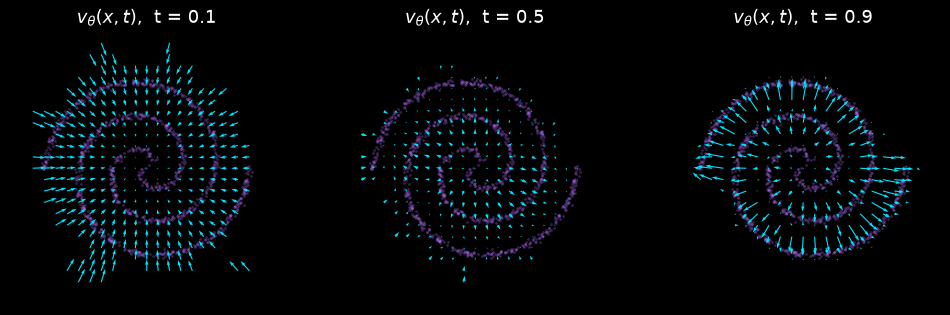

In [18]:
g = torch.linspace(-LIM, LIM, 25)
gx, gy = torch.meshgrid(g, g, indexing="xy")
grid = torch.stack([gx.flatten(), gy.flatten()], dim=1)

def where_xt_lives(t, n=5000, radius=0.3):
    """Grid points within `radius` of a sampled x_t, i.e. where p_t has mass."""
    x1 = spiral[torch.randint(len(spiral), (n,), generator=plot_gen)]
    x0 = torch.randn(n, 2, generator=plot_gen)
    xt = t * x1 + (1 - t) * x0
    return torch.cdist(grid, xt).min(dim=1).values < radius


fig, axes = new_fig(3)
for ax, t in zip(axes, [0.1, 0.5, 0.9]):
    keep = where_xt_lives(t)
    pts = grid[keep]
    with torch.no_grad():
        v = model(pts, torch.full((len(pts),), t))
    scatter(ax, spiral, DATA, alpha=0.3)
    ax.quiver(pts[:, 0], pts[:, 1], v[:, 0], v[:, 1], color=GEN,
              angles="xy", scale_units="xy", scale=8, width=0.004)
    style_ax(ax, f"$v_\\theta(x, t)$,  t = {t}")
save(fig, "vector_field")

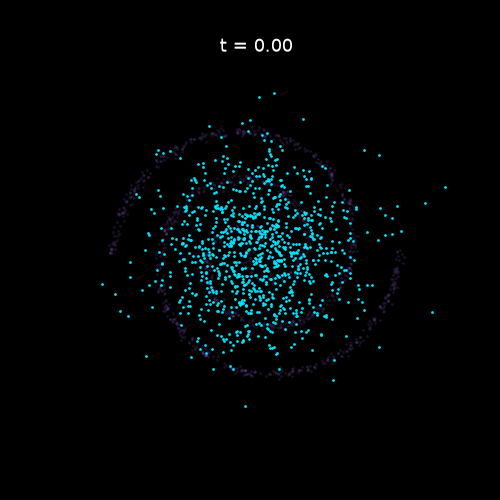

In [19]:
STEPS = 50
path = euler_path(torch.randn(1000, 2, generator=plot_gen), steps=STEPS)

fig, ax = new_fig(size=5)
scatter(ax, spiral, DATA, alpha=0.15)
points = ax.scatter(path[0, :, 0], path[0, :, 1], c=GEN, s=4, linewidths=0)
style_ax(ax, "t = 0.00")

def update(frame):
    points.set_offsets(path[frame])
    ax.set_title(f"t = {frame / STEPS:.2f}", color="white", fontsize=13)
    return (points,)

frames = list(range(STEPS + 1)) + [STEPS] * 20  # hold the last frame
anim = FuncAnimation(fig, update, frames=frames)
anim.save("assets/flow.gif", writer=PillowWriter(fps=15), savefig_kwargs={"facecolor": BG})
plt.close(fig)
Image("assets/flow.gif")